# Single-source Gaussian Process simulation

This notebook combines the three simple Python scripts into one workflow:

1. **Prepare data:** use Andrei's single-source simulation to create a known sound field and 20 simulated phone readings.
2. **Predict:** use a Gaussian Process (GP) to estimate the sound level across the map.
3. **Evaluate:** compare the saved GP prediction with the known field.

Run the cells from top to bottom, or select **Run All** in VS Code/Jupyter. The folders **austin** and **andreib** must remain next to each other. Choose a Python environment with NumPy, Matplotlib and IPython installed.

The figures shown in this copy are previews from the fixed example. Running the notebook again generates the CSV files and PNG figures on your own computer, in the **austin** folder. The numbers describe an ideal simulation in **dB**, not measured phone accuracy or an A-weighted dBA result.

## 0. Locate the project files

A notebook does not have the usual Python script variable called __file__. This cell locates the adjacent folders and sets the path used by the three script sections below.

In [ ]:
from pathlib import Path

current = Path.cwd().resolve()
possible_simulation_folders = [
    current,
    current.parent,
    current / "仿真",
]
simulation_folder = next(
    (p for p in possible_simulation_folders
     if (p / "andreib" / "point_source.py").is_file()
     and (p / "austin").is_dir()),
    None,
)
if simulation_folder is None:
    raise FileNotFoundError(
        "Cannot find the adjacent austin/ and andreib/ folders."
    )
austin_dir = simulation_folder / "austin"
print("Notebook code folder:", austin_dir)

**Output explained:** “Notebook code folder” is the local folder where this notebook will save its PNG figures and CSV files. Its path will look different on each team member's computer; that is expected.

## 1. Prepare the sound field and sample positions

Andrei's model places one stationary source at \((50,50)\) m. For a map position \(\mathbf x=(x,y)\), it uses

$$
d(\mathbf x)=\max\!\left(\sqrt{(x-50)^2+(y-50)^2},1\,\mathrm m\right),
\qquad
L_{\rm true}(\mathbf x)=100-20\log_{10}\!\left(\frac{d(\mathbf x)}{1\,\mathrm m}\right)\ \mathrm{dB}.
$$

The simulation covers 0–100 m in both directions on a 201 × 201 grid. Andrei's data-preparation function chooses 20 random phone locations using seed 42, then reads the sound level at the nearest grid cell. No phone measurement noise is added.

The full field is shown here to explain the test case. It will **not** be passed to the GP prediction function.

In [ ]:
__file__ = str(austin_dir / "gp_single_source.py")

"""Prepare one single-source dataset using Andrei's code. No GP runs here."""

from pathlib import Path
import sys

import matplotlib

matplotlib.use("Agg")  # Save the figure instead of opening a plot window.
import matplotlib.pyplot as plt


# Find Andrei's files in the folder next to austin/.
folder = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(folder / "andreib"))
import point_source
from extract_sound import prepare_interpolation_data


# 1. Use Andrei's sound field to make 20 random phone measurements.
all_data = prepare_interpolation_data(
    point_source.sound_maps,
    point_source.x,
    point_source.y,
    phone_counts=[20],
    layouts=["random"],
    seed=42,
)
data = all_data[(20, "random")]

# 2. Give the four arrays short names.
phone_positions = data["phone_positions"]  # Where the 20 phones are.
phone_levels = data["phone_levels"]        # What the 20 phones measure.
query_positions = data["query_positions"]  # Where we will predict later.
true_levels = data["true_levels"]          # The answer, used only for scoring.

print("Phone positions:", phone_positions.shape)  # (20, 2)
print("Phone levels:", phone_levels.shape)        # (1, 20)
print("Query positions:", query_positions.shape)  # (40401, 2)
print("True levels:", true_levels.shape)          # (1, 40401)

# 3. Draw the complete simulated field and the 20 observed points.
true_map = true_levels[0].reshape(201, 201)
lowest = true_levels.min()
highest = true_levels.max()
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)

image = axes[0].imshow(
    true_map, origin="lower", extent=(0, 100, 0, 100),
    vmin=lowest, vmax=highest,
)
axes[0].scatter(phone_positions[:, 0], phone_positions[:, 1], color="white")
axes[0].set_title("Full sound field and phone positions")

axes[1].scatter(
    phone_positions[:, 0], phone_positions[:, 1],
    c=phone_levels[0], vmin=lowest, vmax=highest, s=70,
)
axes[1].set_title("Only the 20 phone readings")

for axis in axes:
    axis.set(xlim=(0, 100), ylim=(0, 100), xlabel="x (m)", ylabel="y (m)")
    axis.set_aspect("equal")

fig.colorbar(image, ax=axes, label="Level (dB)")
output = Path(__file__).with_name("gp_single_source_inputs.png")
fig.savefig(output, dpi=160)
plt.close("all")
print("Saved figure:", output)


### What the first printed outputs mean

| Printed name | Expected shape | Meaning |
|---|---:|---|
| Phone positions | (20, 2) | The x and y coordinates of 20 simulated phones. |
| Phone levels | (1, 20) | One time frame with one reading from each phone. |
| Query positions | (40401, 2) | The 201 × 201 grid positions where a method must predict. |
| True levels | (1, 40401) | The complete answer, reserved for evaluation. |

“Saved figure” tells you where the first PNG was written. The shape (1, 40401) means **one time frame**, not one sound level.

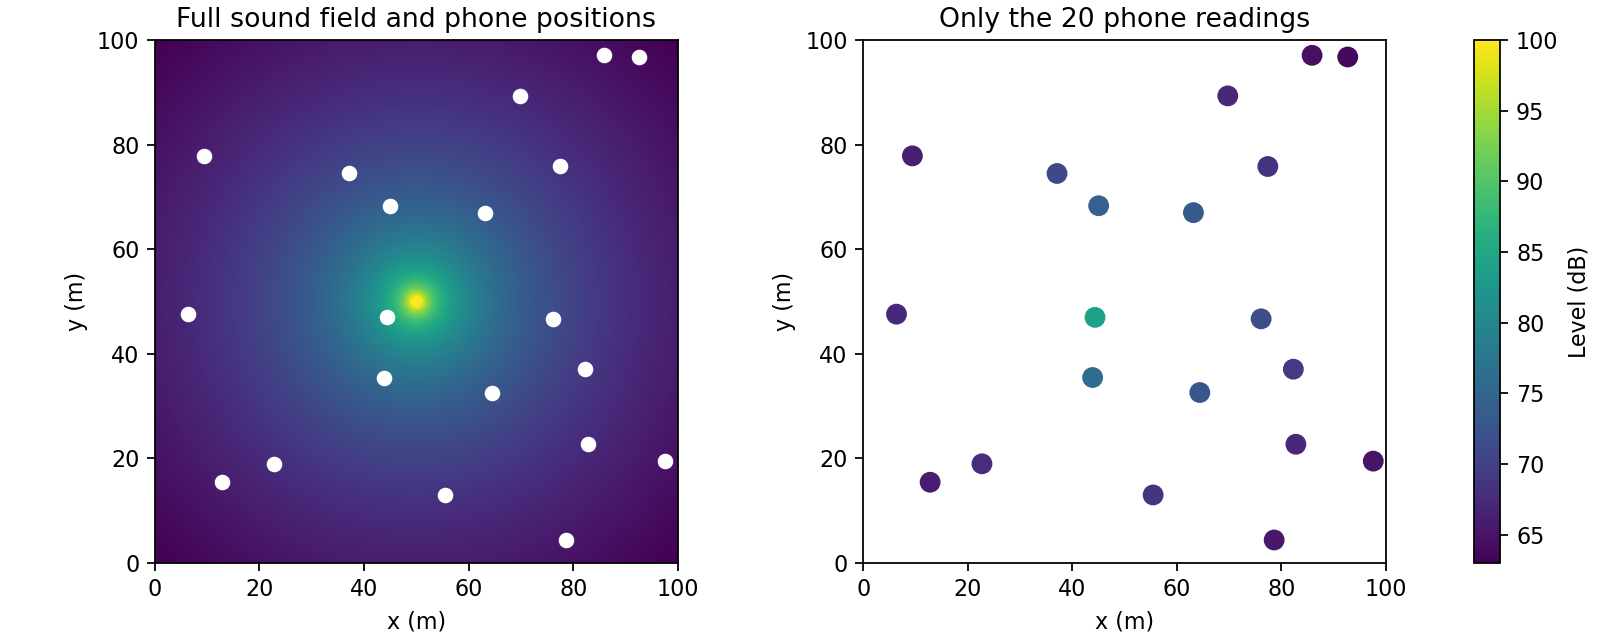

In [ ]:
from IPython.display import Image, display

display(Image(filename=str(austin_dir / "gp_single_source_inputs.png")))

**Figure explained:** The left panel shows Andrei's complete simulated sound field; white dots mark phone locations. The right panel shows only the 20 readings available to a mapping method. Both panels use the same colour scale. The GP in the next step receives the positions and readings, not the complete field shown on the left.

## 2. Predict the map with a GP

The RBF kernel assigns a larger relationship to nearby positions:

$$
k(\mathbf x,\mathbf x')
=\sigma_f^2\exp\!\left(-\frac{\|\mathbf x-\mathbf x'\|^2}{2\ell^2}\right),
\qquad \ell=15\ {\rm m},\quad \sigma_f=15\ {\rm dB}.
$$

With the phone-to-phone kernel matrix \(K\), query-to-phone matrix \(K_*\), phone readings \(\mathbf z\), and their mean \(\bar z\), the code solves

$$
(K+10^{-6}I)\boldsymbol\alpha=\mathbf z-\bar z\mathbf1,
\qquad
\hat{\mathbf f}_*=\bar z\mathbf1+K_*\boldsymbol\alpha.
$$

The values 15 m and 15 dB are starting choices, not fitted parameters. The tiny \(10^{-6}I\) term keeps the calculation stable; it is **not** a realistic model of phone noise. This simple GP returns a **prediction mean only**. It does not yet calculate a prediction uncertainty map.

In [ ]:
__file__ = str(austin_dir / "gp_single_source_step2.py")

"""Step 2: predict the single-source sound map from 20 simulated phone readings."""

from pathlib import Path
import sys

import matplotlib

matplotlib.use("Agg")  # Save a picture without opening a plot window.
import matplotlib.pyplot as plt
import numpy as np


# Andrei's files are in the folder next to austin/.
folder = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(folder / "andreib"))
import point_source
from extract_sound import prepare_interpolation_data


def rbf_kernel(first, second):
    """Give nearby positions a stronger connection than distant positions."""
    length_scale = 15.0  # metres; a starting choice, not a fitted value
    signal_std = 15.0    # dB; a starting choice, not a measured value

    # The result has one row per position in first and one column per position
    # in second. Each entry depends on the squared distance between two points.
    difference = first[:, None, :] - second[None, :, :]
    distance_squared = np.sum(difference**2, axis=2)
    return signal_std**2 * np.exp(
        -distance_squared / (2 * length_scale**2)
    )


def predict_gp(phone_positions, phone_levels, query_positions):
    """Return one predicted sound map per time frame, with shape (T, M)."""
    # K describes how strongly the phone positions are related to each other.
    k_phones = rbf_kernel(phone_positions, phone_positions)
    k_phones += 1e-6 * np.eye(len(phone_positions))  # Numerical stability.

    # K_star describes how each map position is related to the phone positions.
    k_query_phones = rbf_kernel(query_positions, phone_positions)

    maps = []
    for readings in phone_levels:  # The simple example has just one time frame.
        average = readings.mean()
        change_from_average = readings - average
        weights = np.linalg.solve(k_phones, change_from_average)
        predicted_map = average + k_query_phones @ weights
        maps.append(predicted_map)

    return np.array(maps)


# Use exactly the same scene, phone count, layout and seed as Step 1.
data = prepare_interpolation_data(
    point_source.sound_maps,
    point_source.x,
    point_source.y,
    phone_counts=[20],
    layouts=["random"],
    seed=42,
)[(20, "random")]

# Only these three arrays enter the GP. The true map stays out of prediction.
phone_positions = data["phone_positions"]
phone_levels = data["phone_levels"]
query_positions = data["query_positions"]

prediction = predict_gp(phone_positions, phone_levels, query_positions)
print("Prediction shape:", prediction.shape)  # (1, 40401)
print(f"Predicted range: {prediction.min():.3f} to {prediction.max():.3f} dB")

# Save the prediction as a table: x coordinate, y coordinate, predicted level.
output_csv = Path(__file__).with_name("gp_single_source_predictions.csv")
table = np.column_stack((query_positions, prediction[0]))
np.savetxt(
    output_csv, table, delimiter=",",
    header="x_m,y_m,predicted_level_db", comments="", fmt="%.6f",
)

# Draw the GP prediction. White dots mark the 20 readings used by the model.
fig, axis = plt.subplots(figsize=(5, 4))
image = axis.imshow(
    prediction[0].reshape(201, 201),
    origin="lower", extent=(0, 100, 0, 100),
)
axis.scatter(phone_positions[:, 0], phone_positions[:, 1], color="white")
axis.set(title="GP prediction from 20 phone readings",
         xlabel="x (m)", ylabel="y (m)")
fig.colorbar(image, ax=axis, label="Predicted level (dB)")
fig.tight_layout()
output_png = Path(__file__).with_name("gp_single_source_prediction.png")
fig.savefig(output_png, dpi=160)
plt.close("all")

print("Saved table:", output_csv)
print("Saved figure:", output_png)


### What the GP outputs mean

- **Prediction shape (1, 40401):** one predicted value for every grid cell in one time frame.
- **Predicted range:** the smallest and largest GP estimates on this map. For this fixed example, they are about **63.935 to 84.624 dB**. This range describes the GP output, not Andrei's true range.
- **Saved table:** the prediction CSV has three columns: **x_m**, **y_m**, and **predicted_level_db**. Each of its 40,401 rows represents one grid position.
- **Saved figure:** the next PNG visualises those same 40,401 predictions.

Only the phone coordinates, phone readings and query coordinates enter the predict_gp function. The complete true_levels array is not an input.

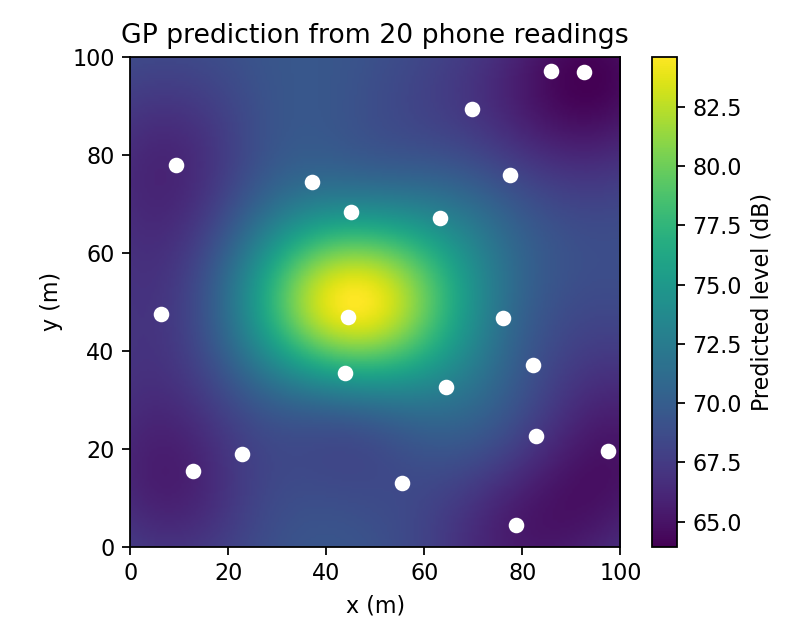

In [ ]:
display(Image(filename=str(austin_dir / "gp_single_source_prediction.png")))

**Figure explained:** Colours show the GP's predicted sound levels, and white dots show the 20 phone locations. This is a **prediction map**, not the true map. Its colour bar scales to the predicted values, so the brightest yellow does **not** mean the source reached its true 100 dB maximum.

## 3. Evaluate the saved prediction

This step reloads the prediction CSV, checks that its coordinates match the reference grid in the same order, and only then reads the known true levels for scoring.

At each grid point, define error as \(e_j=\hat L_j-L_{{\rm true},j}\). Positive error means the GP predicts too high; negative error means it predicts too low.

$$
\mathrm{MAE}=\operatorname{mean}(|e_j|),\qquad
\mathrm{RMSE}=\sqrt{\operatorname{mean}(e_j^2)},\qquad
\mathrm{Bias}=\operatorname{mean}(e_j).
$$

The code also reports the 95th percentile of absolute error, MAE where the **true** level is at least 80 dB, and the difference between the two maps' maximum values. The 80 dB cutoff is an analysis choice for this example, **not** a safety threshold.

In [ ]:
__file__ = str(austin_dir / "gp_single_source_step3.py")

"""Step 3: compare the saved GP map with Andrei's full single-source map."""

import csv
from pathlib import Path
import sys

import matplotlib

matplotlib.use("Agg")  # Save the figure without opening a window.
import matplotlib.pyplot as plt
import numpy as np


# Use the same Andrei scene and data-preparation function as Step 2.
folder = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(folder / "andreib"))
import point_source
from extract_sound import prepare_interpolation_data


# Read the prediction saved by Step 2. This file has x, y and predicted dB.
prediction_csv = Path(__file__).with_name("gp_single_source_predictions.csv")
if not prediction_csv.exists():
    raise FileNotFoundError("Run gp_single_source_step2.py before Step 3.")
prediction_table = np.loadtxt(prediction_csv, delimiter=",", skiprows=1)

# Get the hidden truth only now, after the GP prediction has been saved.
data = prepare_interpolation_data(
    point_source.sound_maps,
    point_source.x,
    point_source.y,
    phone_counts=[20],
    layouts=["random"],
    seed=42,
)[(20, "random")]
query_positions = data["query_positions"]
true_levels = data["true_levels"][0]  # One time frame, 40,401 grid points.

# Check that each CSV prediction is paired with the correct truth position.
if prediction_table.shape != (len(true_levels), 3):
    raise ValueError("The prediction CSV does not match the Step 2 grid size.")
if not np.allclose(prediction_table[:, :2], query_positions, atol=1e-6, rtol=0):
    raise ValueError("The prediction CSV coordinates do not match Andrei's grid.")
predicted_levels = prediction_table[:, 2]
if not np.all(np.isfinite(predicted_levels)):
    raise ValueError("The prediction CSV contains invalid sound levels.")

# A positive error means the GP predicted too high; negative means too low.
error = predicted_levels - true_levels
absolute_error = np.abs(error)
mae = np.mean(absolute_error)
rmse = np.sqrt(np.mean(error**2))
bias = np.mean(error)
p95 = np.percentile(absolute_error, 95)

# 80 dB is an example analysis threshold for this scene, not a safety limit.
high_threshold = 80.0
high_points = true_levels >= high_threshold
high_mae = np.mean(absolute_error[high_points])

# Compare the two peak heights. Andrei's source has several equally high
# centre cells, so picking just the first maximum cell would be arbitrary.
peak_gap = np.max(predicted_levels) - np.max(true_levels)

metrics = [
    ("MAE", mae, "dB"),
    ("RMSE", rmse, "dB"),
    ("Bias (predicted - true)", bias, "dB"),
    ("P95 absolute error", p95, "dB"),
    ("MAE where true level >= 80 dB", high_mae, "dB"),
    ("Peak level gap (predicted max - true max)", peak_gap, "dB"),
]

# Save the numbers so later methods can use the same scoring columns.
metrics_csv = Path(__file__).with_name("gp_single_source_step3_metrics.csv")
with metrics_csv.open("w", newline="") as file:
    writer = csv.writer(file)
    writer.writerow(["metric", "value", "unit"])
    for name, value, unit in metrics:
        writer.writerow([name, f"{value:.6f}", unit])

print(f"Compared {len(true_levels)} grid points.")
for name, value, unit in metrics:
    print(f"{name}: {value:.3f} {unit}")
print(f"High-level points (true >= 80 dB): {np.sum(high_points)}")

# Use one colour scale for truth and prediction so their colours are comparable.
map_shape = point_source.sound_maps.shape[1:]  # (201, 201)
colour_min = min(true_levels.min(), predicted_levels.min())
colour_max = max(true_levels.max(), predicted_levels.max())
extent = (point_source.x.min(), point_source.x.max(),
          point_source.y.min(), point_source.y.max())
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)

for axis, levels, title in zip(
    axes[:2], (true_levels, predicted_levels), ("Andrei's truth", "GP prediction")
):
    image = axis.imshow(levels.reshape(map_shape), origin="lower", extent=extent,
                        vmin=colour_min, vmax=colour_max)
    axis.set(title=title, xlabel="x (m)", ylabel="y (m)")
fig.colorbar(image, ax=axes[:2], label="Sound level (dB)", shrink=0.85)

error_image = axes[2].imshow(absolute_error.reshape(map_shape), origin="lower",
                             extent=extent, vmin=0)
axes[2].set(title="Absolute error", xlabel="x (m)", ylabel="y (m)")
fig.colorbar(error_image, ax=axes[2], label="Error (dB)", shrink=0.85)

figure_png = Path(__file__).with_name("gp_single_source_step3_comparison.png")
fig.savefig(figure_png, dpi=160)
plt.close("all")

print("Saved metrics:", metrics_csv)
print("Saved figure:", figure_png)


### What the evaluation outputs mean

| Printed metric | About this run | Simple interpretation |
|---|---:|---|
| Compared grid points | 40,401 | Every cell in the 201 × 201 map was scored. |
| MAE | 1.037 dB | Average size of the error across the whole map. |
| RMSE | 1.571 dB | Gives larger errors more influence than MAE. |
| Bias | +0.584 dB | The GP is slightly high on average. |
| P95 absolute error | 3.371 dB | About 95% of cells have absolute error at or below this value. |
| High-level MAE | 2.575 dB | Average error among the 1,257 cells whose true level is at least 80 dB. |
| Peak level gap | −15.376 dB | The GP's maximum is much lower than the true maximum. |

The **peak level gap** compares the two maps' maximum values; those maxima do not have to occur at the same location. “Saved metrics” points to a CSV with the six metric names, values and units. “Saved figure” points to the three-panel comparison PNG. Small differences in displayed decimals may come from rounding when the prediction CSV is saved.

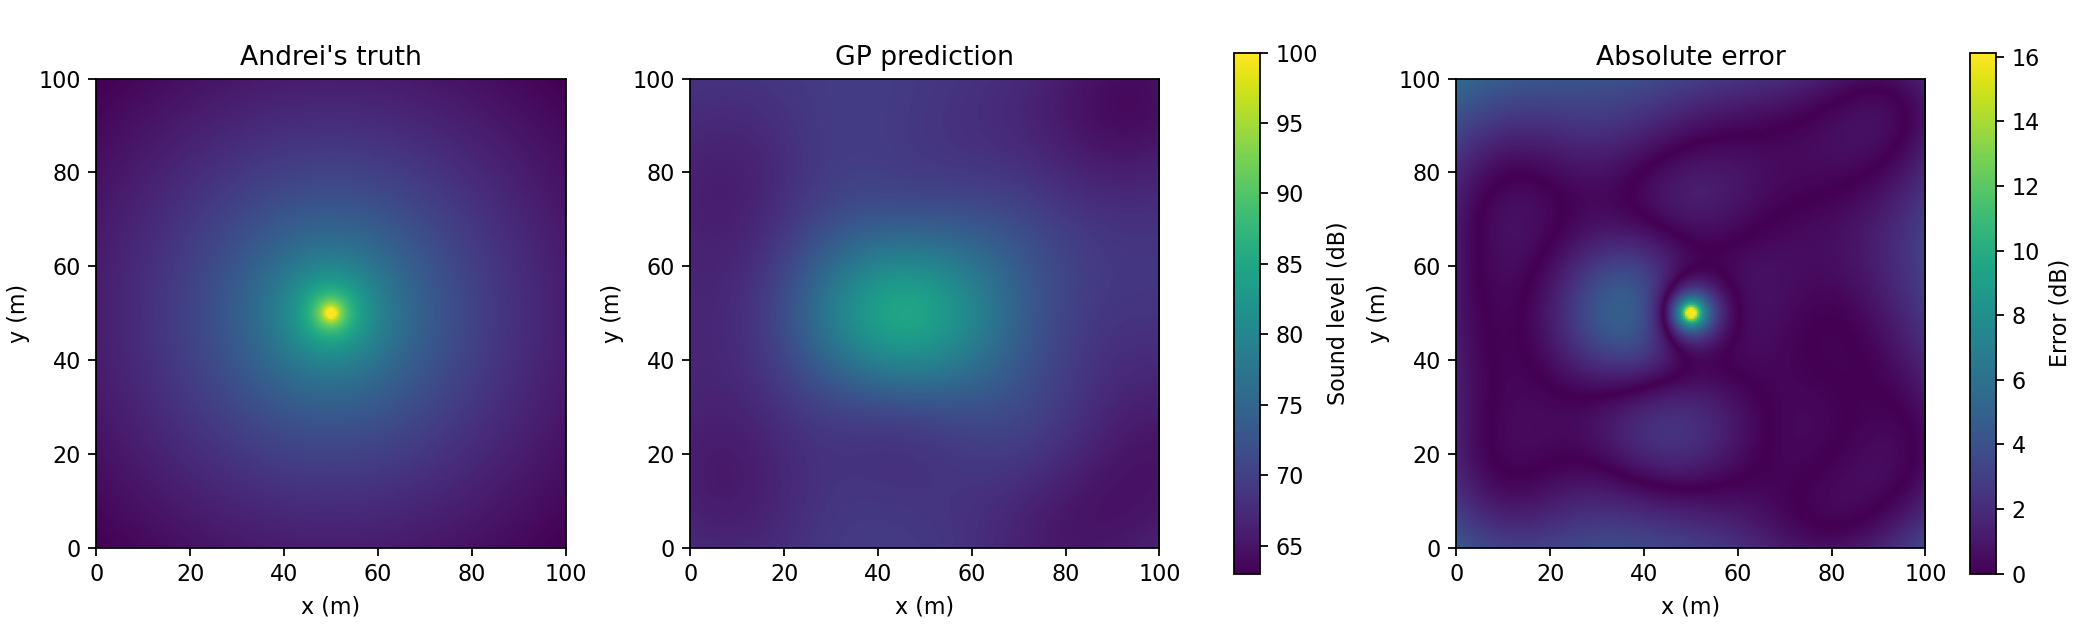

In [ ]:
display(Image(filename=str(austin_dir / "gp_single_source_step3_comparison.png")))

**Figure explained:** The first panel is Andrei's true field; the second is the GP estimate. They share the **same colour scale**, so their colours can be compared directly. The third panel shows **absolute error**: brighter areas mean a larger difference, without indicating whether the GP is high or low. The bright spot near the source shows the missed peak. A low whole-map MAE can therefore coexist with a large local error.

### What this example does and does not establish

The notebook shows that the data flow and basic GP calculation run correctly for **one** static source, **20** random ideal readings and **seed 42**. It does not establish real phone accuracy or that GP is better than another mapping method. Future comparisons should keep the same observations and scoring grid across methods, then repeat over more seeds and layouts.